# Wheat_portfolio — allocation sur le blé en walk-forward

On parcourt le temps mois par mois. À chaque date *t*, chaque modèle choisit une position $w_t \in [-1, 1]$ sur le blé (fraction du capital ; négative = vente à découvert), sous une **contrainte de risque** : volatilité annualisée ex ante au plus égale à $\sigma$. On compare la valeur de 1 $ investi à :
- **1 $ de blé conservé** depuis la première date (buy & hold) ;
- une **position qui suit une marche aléatoire** (1 000 trajectoires) ;
- une position **longue à risque σ** (toujours acheteur, taille maximale autorisée).

### Calendrier des décisions (pas de look-ahead)
| Moment | Ce qui se passe |
|---|---|
| fin du mois *t − 1* | on connaît le blé, le WTI, le dollar et le sentiment WASDE jusqu'à *t − 1*, et le RONI jusqu'à *t − 2* (il est publié le mois suivant) ; on calcule $w_t$ |
| mois *t* | la position est construite au prix moyen du mois $P_t$ |
| mois *t + 1* | elle est dénouée au prix moyen $P_{t+1}$ : rendement $R_{t+1} = P_{t+1}/P_t - 1$ |

Les prix du FMI sont des moyennes mensuelles : une position décidée fin *t − 1* ne peut pas être exécutée au prix moyen de *t − 1*, déjà écoulé.

### Calcul de la position
1. **Prévision** $\hat y_t$ du rendement log du mois suivant, par un modèle ré-estimé chaque mois sur le passé connu.
2. **Conviction** $c_t = \tanh\big((\hat y_t - m_t) / s_t\big)$ dans $]-1, 1[$, où $m_t$ et $s_t$ sont la moyenne et l'écart-type des prévisions du modèle sur son échantillon d'apprentissage. Une prévision nettement au-dessus (au-dessous) de l'habitude donne une conviction proche de +1 (−1), une prévision banale une position faible. Le centrage retire la dérive moyenne du blé : la position exprime le pari propre du modèle, et la dérive est mesurée à part par le repère « long à risque σ ».
3. **Ciblage de volatilité** : $w^*_t = \text{clip}(c_t \cdot \sigma / \hat\sigma_t, -1, 1)$, où $\hat\sigma_t$ est la volatilité du blé sur les 36 derniers mois connus. À conviction maximale, la volatilité ex ante vaut σ.
4. **Lissage** : $w_t = \lambda w_{t-1} + (1 - \lambda) w^*_t$, pour limiter les allers-retours et les coûts.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SIGMA_TARGET = 0.10   # risque imposé : volatilité annualisée cible
VOL_WINDOW = 36       # mois d'historique pour estimer la volatilité du blé
MIN_TRAIN = 60        # mois d'apprentissage minimum avant la première position
SMOOTH = 0.5          # lambda du lissage de la position
COST = 0.001          # coût de transaction par unité de position échangée (10 points de base)
N_PATHS, RW_STEP, SEED = 1000, 0.25, 0   # marche aléatoire : trajectoires, écart-type du pas, graine
# variable -> (colonne, transformation, décalages en mois). RONI de t-1 publié en t : décalage >= 2
FEATURES = {
    "wheat": ("wheat_price_usd", "dlog", (1, 2, 3)),
    "wti":   ("wti_price_usd", "dlog", (1, 2, 3)),
    "dxy":   ("dxy_index", "dlog", (1, 2, 3)),
    "roni":  ("roni_index", "level", (2, 3, 4)),
    "sent":  ("wasde_sentiment", "level", (1, 2, 3)),
}

# Panel mensuel exporté par Wheat_analysis.ipynb (à exécuter d'abord)
panel = pd.read_csv("data/cache/monthly_panel.csv", index_col="date", parse_dates=True)
# Mois sans rapport WASDE : on garde le dernier rapport publié, qui est l'information disponible à cette date
panel["wasde_sentiment"] = panel["wasde_sentiment"].ffill()
START = panel["wasde_sentiment"].first_valid_index()

INK2, MUTED, GRID, SURFACE = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "xtick.color": MUTED,
                     "ytick.color": MUTED, "legend.frameon": False, "font.size": 10})

## 1. Données
Ligne *t* : la cible `y` est le rendement log du blé entre *t* et *t + 1*, que touche la position décidée en *t*. Les variables explicatives sont toutes datées *t − 1* ou avant : rendements passés du blé, Δlog WTI, Δlog dollar, RONI et sentiment WASDE, chacun avec 3 décalages.

In [2]:
def prepare(panel):
    logp = np.log(panel["wheat_price_usd"])
    data = pd.DataFrame({"y": logp.shift(-1) - logp})
    for name, (col, kind, lags) in FEATURES.items():
        base = np.log(panel[col]).diff() if kind == "dlog" else panel[col]
        for k in lags:
            data[f"{name}_{k}"] = base.shift(k)
    # volatilité annualisée estimée avec les rendements jusqu'à t-1 inclus
    data["sigma_hat"] = logp.diff().shift(1).rolling(VOL_WINDOW).std() * np.sqrt(12)
    return data.loc[START:].dropna(subset=["y"])

data = prepare(panel)
assert len(data) == len(pd.date_range(data.index[0], data.index[-1], freq="MS")), "mois manquants"
R = np.exp(data["y"]) - 1   # rendement simple réalisé par la position décidée en t
cols_of = lambda *names: [c for c in data if c.split("_")[0] in names]
print(f"Dates de décision : {data.index[0]:%Y-%m} -> {data.index[-1]:%Y-%m} ({len(data)} mois)")

Dates de décision : 1998-02 -> 2026-09 (344 mois)


## 2. Modèles et walk-forward
La cible de la ligne *s* n'est connue qu'en *s + 1*. À la décision *t*, seules les lignes *s* ≤ *t − 2* servent donc à l'apprentissage. Tous les réglages se font à l'intérieur de cet échantillon : la normalisation et le paramètre de régularisation de la Ridge (validation croisée chronologique). Les hyperparamètres du gradient boosting sont fixés a priori (arbres peu profonds) et ne sont pas optimisés sur la période.

| Modèle | Variables |
|---|---|
| Ridge — marché + météo | blé, WTI, dollar, RONI |
| Ridge — marché + météo + NLP | idem + sentiment WASDE |
| Gradient boosting — marché + météo + NLP | idem, modèle non linéaire |

In [3]:
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=TimeSeriesSplit(5)))
hgb = lambda: HistGradientBoostingRegressor(max_depth=2, learning_rate=0.05, max_iter=150, min_samples_leaf=20, random_state=0)
MARKET, FULL = ("wheat", "wti", "dxy", "roni"), ("wheat", "wti", "dxy", "roni", "sent")
MODELS = {
    "Ridge — marché + météo": (MARKET, ridge),
    "Ridge — marché + météo + NLP": (FULL, ridge),
    "Gradient boosting — marché + météo + NLP": (FULL, hgb),
}
MAIN = "Ridge — marché + météo + NLP"

def walk_forward(data, cols, make_model):
    out = pd.DataFrame(np.nan, index=data.index, columns=["pred", "center", "scale"])
    for i, t in enumerate(data.index):
        train = data.iloc[:max(i - 1, 0)].dropna(subset=cols + ["y"])   # lignes s <= t-2
        if len(train) < MIN_TRAIN or data.loc[t, cols].isna().any():
            continue
        model = make_model().fit(train[cols], train["y"])
        fitted = model.predict(train[cols])
        out.loc[t] = model.predict(data.loc[[t], cols])[0], fitted.mean(), fitted.std()
    return out

def position(data, wf):
    conviction = np.tanh((wf["pred"] - wf["center"]) / wf["scale"].replace(0, np.nan))
    target = (conviction * SIGMA_TARGET / data["sigma_hat"]).clip(-1, 1).fillna(0)
    return target.ewm(alpha=1 - SMOOTH, adjust=False).mean()   # w_t = λ w_{t-1} + (1-λ) w*_t

def run(data, models):
    return pd.DataFrame({name: position(data, walk_forward(data, cols_of(*names), make))
                         for name, (names, make) in models.items()})

positions = run(data, MODELS)
first = max(positions[c].ne(0).idxmax() for c in positions)   # première date où tous les modèles ont une position
print(f"Positions à partir de {first:%Y-%m} ({(data.index >= first).sum()} mois de trading)")

Positions à partir de 2003-06 (280 mois de trading)


## 3. Repères et performance
Le P&L de la ligne *t* vaut $w_t R_{t+1}$, moins un coût proportionnel à $|w_t - w_{t-1}|$ ; le cash rapporte 0 %. Les indicateurs sont calculés sur la **période de trading** pour toutes les stratégies, y compris le buy & hold.

Marche aléatoire : exposition $u_t = \text{clip}(u_{t-1} + \varepsilon_t, -1, 1)$, avec $\varepsilon_t \sim \mathcal{N}(0, 0{,}25^2)$, mise à l'échelle par $\sigma / \hat\sigma_t$ comme les modèles.

In [4]:
trading = pd.Series(data.index >= first, index=data.index)
risk_scale = (SIGMA_TARGET / data["sigma_hat"]).clip(upper=1)
benchmarks = pd.DataFrame({"Long blé à risque σ": risk_scale.where(trading, 0)})

rng = np.random.default_rng(SEED)
steps = rng.normal(0, RW_STEP, (len(data), N_PATHS))
u = np.zeros_like(steps)
for i in range(1, len(u)):
    u[i] = np.clip(u[i - 1] + steps[i], -1, 1)
rw_positions = pd.DataFrame(u, index=data.index).mul(risk_scale * trading, axis=0).fillna(0)

def pnl(w):
    return w.mul(R, axis=0) - COST * w.diff().abs().fillna(w.abs())

def wealth(p):   # valeur de 1 $ ; le résultat de la ligne t est réalisé en t+1
    v = (1 + p).cumprod()
    v.index = v.index + pd.offsets.MonthBegin(1)
    return pd.concat([p.iloc[:1] * 0 + 1, v])

def metrics(p):
    p = p.loc[first:]
    v = (1 + p).cumprod()
    return pd.Series({"rendement annualisé": v.iloc[-1] ** (12 / len(p)) - 1,
                      "volatilité annualisée": p.std() * np.sqrt(12),
                      "ratio de Sharpe": p.mean() / p.std() * np.sqrt(12),
                      "perte maximale": (v / v.cummax() - 1).min()})

pnls = {"Buy & hold (1 $ de blé)": R, **{c: pnl(positions[c]) for c in positions}, **{c: pnl(benchmarks[c]) for c in benchmarks}}
rw_sharpe = pnl(rw_positions).apply(metrics).loc["ratio de Sharpe"]
table = pd.DataFrame({k: metrics(v) for k, v in pnls.items()}).T
table["part des marches aléatoires au Sharpe supérieur"] = [(rw_sharpe >= s).mean() for s in table["ratio de Sharpe"]]
table.loc["Marche aléatoire (médiane)"] = pnl(rw_positions).apply(metrics).median(axis=1)
w = pd.concat([positions, benchmarks], axis=1).loc[first:]
table["|position| moyenne"] = w.abs().mean()
table["rotation mensuelle"] = w.diff().abs().mean()
table["taux de bon signe"] = (np.sign(w).eq(np.sign(R.loc[first:]), axis=0)).mean()
display(table.round(3))

,rendement annualisé,volatilité annualisée,ratio de Sharpe,perte maximale,part des marches aléatoires au Sharpe supérieur,|position| moyenne,rotation mensuelle,taux de bon signe
Buy & hold (1 $ de blé),0.026,0.254,0.229,-0.697,0.183,NaN,NaN,NaN
Ridge — marché + météo,0.009,0.061,0.182,-0.326,0.222,0.184,0.077,0.529
Ridge — marché + météo + NLP,-0.001,0.060,0.015,-0.355,0.458,0.180,0.082,0.511
Gradient boosting — marché + météo + NLP,0.003,0.039,0.099,-0.183,0.330,0.135,0.110,0.536
Long blé à risque σ,0.026,0.109,0.289,-0.381,0.135,0.423,0.010,0.507
Marche aléatoire (médiane),-0.003,0.070,-0.013,-0.382,NaN,NaN,NaN,NaN


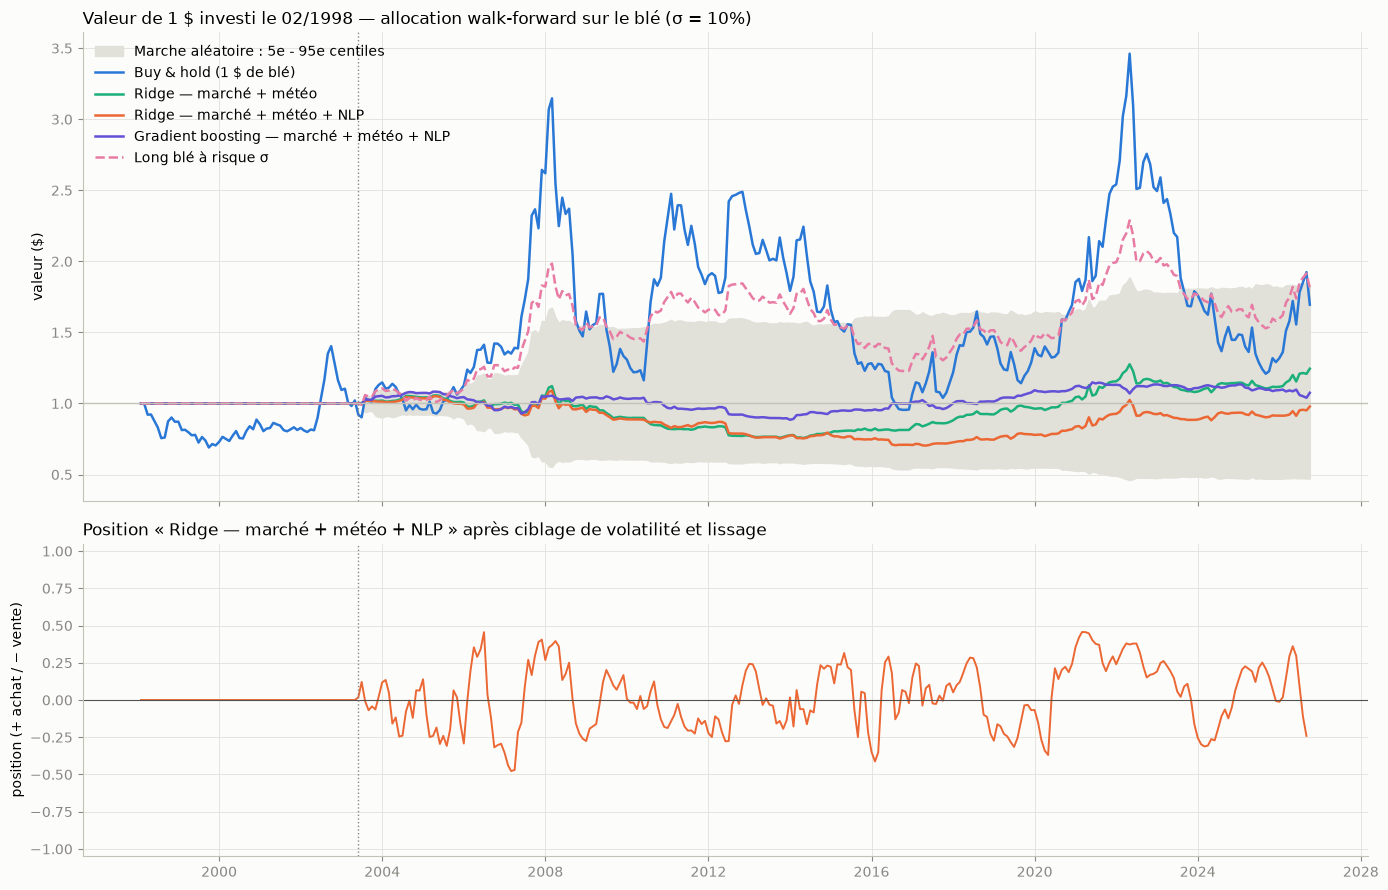

In [5]:
values = pd.DataFrame({k: wealth(v) for k, v in pnls.items()})
rw_values = wealth(pnl(rw_positions))
styles = {"Buy & hold (1 $ de blé)": ("#2a78d6", "-"), "Ridge — marché + météo": ("#1baf7a", "-"),
          "Ridge — marché + météo + NLP": ("#eb6834", "-"), "Gradient boosting — marché + météo + NLP": ("#6250d6", "-"),
          "Long blé à risque σ": ("#e87ba4", "--")}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.fill_between(rw_values.index, rw_values.quantile(0.05, axis=1), rw_values.quantile(0.95, axis=1),
                 color=GRID, label="Marche aléatoire : 5e - 95e centiles")
for name, (color, ls) in styles.items():
    ax1.plot(values.index, values[name], color=color, ls=ls, lw=1.8, label=name)
ax1.axhline(1, color="#c3c2b7", lw=1)
ax1.set_title(f"Valeur de 1 $ investi le {START:%m/%Y} — allocation walk-forward sur le blé (σ = {SIGMA_TARGET:.0%})")
ax1.set_ylabel("valeur ($)")
ax1.legend(loc="upper left")

ax2.plot(positions.index, positions[MAIN], color="#eb6834", lw=1.4, label=MAIN)
ax2.axhline(0, color=INK2, lw=0.8)
ax2.set_ylim(-1.05, 1.05)
ax2.set_title(f"Position « {MAIN} » après ciblage de volatilité et lissage")
ax2.set_ylabel("position (+ achat / − vente)")
for ax in (ax1, ax2):
    ax.axvline(first, color=MUTED, ls=":", lw=1)
fig.tight_layout()
plt.show()

## 4. Contrôle anti look-ahead
Test placebo : on remplace toutes les données à partir de `T0` par du bruit et on relance le modèle principal. Si aucune information future n'est utilisée, les positions décidées jusqu'à `T0` inclus doivent être identiques.

In [6]:
T0 = pd.Timestamp("2015-01-01")
noisy = panel.copy()
after = noisy.index >= T0
noisy.loc[after] = noisy.loc[after].mask(noisy.loc[after].notna(),
                                         np.abs(np.random.default_rng(1).normal(50, 20, noisy.loc[after].shape)))
check = run(prepare(noisy), {MAIN: MODELS[MAIN]})[MAIN]
print(f"Positions jusqu'à {T0:%Y-%m} identiques : {np.allclose(check.loc[:T0], positions.loc[:T0, MAIN])} ; "
      f"positions après modifiées : {not np.allclose(check.loc[T0:].iloc[1:], positions.loc[T0:, MAIN].iloc[1:])}")

Positions jusqu'à 2015-01 identiques : True ; positions après modifiées : True


## Hypothèses et limites
- **Exécution** : au prix moyen du mois (achats et ventes étalés), sans contrat à terme ni coût de portage ; cash à 0 % ; vente à découvert sans coût ; coûts de 10 points de base par unité échangée.
- **Risque** : la contrainte est respectée *ex ante* ($|w_t| \hat\sigma_t \le \sigma$) ; la volatilité réalisée peut s'en écarter, car $\hat\sigma_t$ est estimée sur le passé.
- **Paramètres fixés a priori** (σ, λ, fenêtres, hyperparamètres du gradient boosting) : les faire varier pour juger de la robustesse, sans les choisir d'après la performance de la période.
- **Données** : séries actuelles et non telles que publiées à l'époque (révisions éventuelles du FMI et du RONI).